# 01 · Data overview, quality checks and trend drivers

**Shop Stats** is a synthetic online store: 24 months of traffic (Nov 2024 – Oct 2026), ~24M sessions,
3.3M users, 1.2M orders. The generator (`src/generate_data.py`) plants a growth trend, seasonality,
12 promotions, 18 internal / external events and two A/B tests. `data/events_calendar.csv` is the
ground truth we use to *explain* what the analysis finds.

This notebook: (1) describes the tables, (2) runs integrity checks, (3) builds the daily aggregates the
other notebooks and the Excel workbook reuse, (4) decomposes the daily series into trend, seasonality
and event effects with significance tests.

In [1]:
import sys, warnings
sys.path.insert(0, "../src"); sys.path.insert(0, "src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
import shopstats as ss
from shopstats import *
set_style()
pd.options.display.float_format = "{:,.4f}".format
pd.set_option("display.width", 250, "display.max_columns", 40, "display.max_colwidth", 70)
try:
    display
except NameError:
    display = print

## 1. Tables

In [2]:
S = load_sessions()
O = load_orders()
I = pd.read_parquet(DATA / "order_items.parquet")
U = pd.read_parquet(DATA / "users.parquet")
P = pd.read_parquet(DATA / "products.parquet")
EV, PR = load_events()
tables = {"sessions": S, "orders": O, "order_items": I, "users": U, "products": P, "promotions": PR, "events_calendar": EV}
display(pd.DataFrame({"rows": {k: len(v) for k, v in tables.items()},
                      "columns": {k: v.shape[1] for k, v in tables.items()}}))

,rows,columns
sessions,23876905,22
orders,1179166,23
order_items,1826468,9
users,3322191,8
products,3000,6
promotions,12,8
events_calendar,24,7


In [3]:
for name in ["sessions", "orders", "order_items", "users", "products"]:
    print(f"\n=== {name} ===")
    display(tables[name].head(3))


=== sessions ===


,session_id,user_id,session_start,channel,device,country,is_new_user,is_loyalty_member,pageviews,duration_sec,viewed_category,viewed_product_id,viewed_product,added_to_cart,began_checkout,entered_payment,purchased,payment_method,ab_test,ab_variant,order_id,day
0,1,402256,2024-11-01 00:00:04,Direct,mobile,AU,True,False,5,177,Beauty,1851,True,False,False,False,False,NaN,NaN,NaN,<NA>,0
1,2,357540,2024-11-01 00:00:08,Direct,mobile,US,False,False,4,29,Toys & Games,2522,True,False,False,False,False,NaN,NaN,NaN,<NA>,0
2,3,398053,2024-11-01 00:00:09,Affiliate,desktop,US,False,False,1,27,NaN,<NA>,False,False,False,False,False,NaN,NaN,NaN,<NA>,0



=== orders ===


,order_id,session_id,user_id,order_ts,country,device,channel,payment_method,promo_id,n_lines,units,gross_amount,discount_amount,revenue,shipping_fee,cogs,status,delivery_days,delivered_date,refund_amount,review_rating,day,profit
0,1,32,196325,2024-11-01 00:17:50,UK,desktop,Email,paypal,NaN,1,1,59.9900,0.0000,59.9900,5.9900,19.8000,delivered,3,2024-11-04,0.0000,5.0000,0,40.1900
1,2,42,191049,2024-11-01 00:27:13,UK,desktop,Direct,paypal,NaN,1,1,10.9900,0.0000,10.9900,5.9900,8.2700,delivered,4,2024-11-05,0.0000,<NA>,0,2.7200
2,3,75,123989,2024-11-01 00:23:17,US,desktop,Organic Search,card,NaN,1,1,6.9900,0.0000,6.9900,5.9900,4.3600,delivered,5,2024-11-06,0.0000,<NA>,0,2.6300



=== order_items ===


,order_id,product_id,category,quantity,list_price,discount_pct,unit_price_paid,unit_cost,returned
0,1,1855,Beauty,1,59.9900,0.0000,59.9900,19.8000,False
1,2,2604,Books & Media,1,10.9900,0.0000,10.9900,8.2700,False
2,3,2692,Books & Media,1,6.9900,0.0000,6.9900,4.3600,False



=== users ===


,user_id,signup_date,country,age_group,gender,acquisition_channel,preferred_device,loyalty_join_date
0,1,2024-06-23,US,18-24,F,Affiliate,mobile,NaT
1,2,2023-12-04,CA,25-34,M,Organic Search,mobile,NaT
2,3,2024-07-01,NL,35-44,F,Organic Search,mobile,NaT



=== products ===


,product_id,product_name,category,base_price,unit_cost,launch_date
0,1,Electronics-0001,Electronics,65.9900,53.0200,2024-09-13
1,2,Electronics-0002,Electronics,96.9900,77.8400,2024-09-15
2,3,Electronics-0003,Electronics,385.9900,337.2500,2024-05-19


**Life-cycle stages.** A session carries five funnel flags (`viewed_product → added_to_cart →
began_checkout → entered_payment → purchased`). A purchase creates an order, whose post-purchase stages
are in `orders` (`status`, `delivery_days`, `refund_amount`, `review_rating`) and `order_items` (`returned`).

## 2. Integrity checks

In [4]:
checks = {
    "session_id unique": S["session_id"].is_unique,
    "order_id unique": O["order_id"].is_unique,
    "orders.session_id ⊂ sessions": bool(O["session_id"].between(1, len(S)).all()),
    "order_items.order_id ⊂ orders": bool(I["order_id"].between(1, len(O)).all()),
    "order_items.product_id ⊂ products": bool(I["product_id"].between(1, len(P)).all()),
    "every purchase session has an order": int(S["purchased"].sum()) == len(O),
    "no negative revenue": bool((O["revenue"] >= 0).all()),
    "revenue = gross − discount": bool(np.allclose(O["revenue"], O["gross_amount"] - O["discount_amount"], atol=0.02)),
}
display(pd.Series(checks, name="passed").to_frame())

,passed
session_id unique,True
order_id unique,True
orders.session_id ⊂ sessions,True
order_items.order_id ⊂ orders,True
order_items.product_id ⊂ products,True
every purchase session has an order,True
no negative revenue,True
revenue = gross − discount,True


### 2.1 Funnel monotonicity
Every stage should imply the previous one. A session that purchased without a recorded add-to-cart is
logically impossible, so any such row is a **tracking problem**, not behaviour.

In [5]:
viol = S["began_checkout"] & ~S["added_to_cart"]
print(f"sessions with checkout but no recorded add-to-cart: {viol.sum():,} ({viol.mean():.4%})")
v = S.loc[viol].groupby(["day", "device"], observed=True).size().unstack(fill_value=0)
v.index = DAYS[v.index]
display(v)
base = S.loc[S["device"].eq("desktop") & S["day"].between(day_index("2025-09-21"), day_index("2025-10-04"))]
bug = S.loc[S["device"].eq("desktop") & S["day"].between(day_index("2025-10-05"), day_index("2025-10-07"))]
r = two_prop(base["added_to_cart"].sum(), base["viewed_product"].sum(), bug["added_to_cart"].sum(), bug["viewed_product"].sum())
print(f"desktop view→cart rate: prior 2 weeks {r['p1']:.3%} vs 5–7 Oct 2025 {r['p2']:.3%} "
      f"(relative {r['lift']:+.1%}, z={r['z']:.1f}, p={fmt_p(r['p'])})")
r2 = two_prop(base["purchased"].sum(), len(base), bug["purchased"].sum(), len(bug))
print(f"desktop purchase rate:  prior 2 weeks {r2['p1']:.3%} vs 5–7 Oct 2025 {r2['p2']:.3%} (p={r2['p']:.3f})")

sessions with checkout but no recorded add-to-cart: 2,347 (0.0098%)


device,desktop
2025-10-05,827
2025-10-06,737
2025-10-07,783


desktop view→cart rate: prior 2 weeks 23.210% vs 5–7 Oct 2025 7.128% (relative -69.3%, z=-56.3, p=<1e-300)
desktop purchase rate:  prior 2 weeks 7.213% vs 5–7 Oct 2025 7.148% (p=0.675)


All violations sit on **desktop, 5–7 Oct 2025**: the recorded add-to-cart rate drops by ~70% while the
purchase rate does not move. Customers behaved normally; the add-to-cart *event* was not logged
(calendar event E08). Any cart-stage metric for those three days must be treated as missing data.

### 2.2 Zero-engagement sessions (bots)

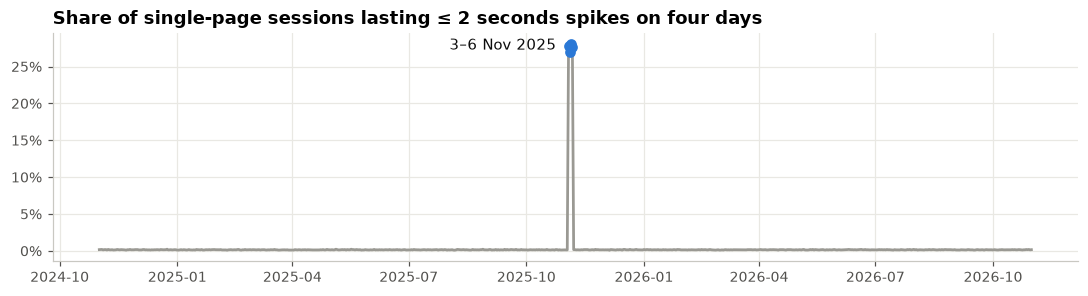

profile of zero-engagement sessions on 3–6 Nov 2025:


channel,Direct,Organic Search,Paid Search
share by channel,0.9967,0.0014,0.0007


device,desktop,mobile,tablet
share by device,0.9972,0.0025,0.0003


hour-of-day profile vs normal traffic: chi2=65,791, p=<1e-300 (bots are flat across the night; humans are not)


In [6]:
S["bounce0"] = (S["pageviews"] == 1) & (S["duration_sec"] <= 2)
b = S.groupby("day")["bounce0"].agg(["sum", "mean"])
b.index = DAYS[b.index]
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.plot(b.index, b["mean"], color=GREY)
top = b["mean"].nlargest(4).sort_index()
ax.plot(top.index, top.values, "o", color=BLUE)
ax.annotate("3–6 Nov 2025", (top.index[0], top.max()), xytext=(-78, -4), textcoords="offset points", color=INK)
ax.set_title("Share of single-page sessions lasting ≤ 2 seconds spikes on four days")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
save(fig, "01_bot_share")
bots = S[S["bounce0"] & S["day"].between(day_index("2025-11-03"), day_index("2025-11-06"))]
print("profile of zero-engagement sessions on 3–6 Nov 2025:")
display(bots["channel"].value_counts(normalize=True).head(3).rename("share by channel").to_frame().T)
display(bots["device"].value_counts(normalize=True).rename("share by device").to_frame().T)
hourly = bots.groupby(bots["session_start"].dt.hour).size()
norm = S.loc[S["day"].between(day_index("2025-10-20"), day_index("2025-11-02"))].groupby(S["session_start"].dt.hour).size()
chi = stats.chisquare(hourly, f_exp=norm / norm.sum() * hourly.sum())
print(f"hour-of-day profile vs normal traffic: chi2={chi.statistic:,.0f}, p={fmt_p(chi.pvalue)} "
      f"(bots are flat across the night; humans are not)")

Roughly 49k extra sessions on 3–6 Nov 2025 are Direct / desktop, one page, ≤ 2 seconds, spread evenly over 24 hours —
an automated **bot wave** (E09). We keep a `suspected_bot` flag (`pageviews == 1` and `duration ≤ 2s`
inside that window) and exclude those rows from user-level statistics. Outside the window the same
pattern is ~0.1% of traffic (fast human bounces), so the flag is only applied inside it.

In [7]:
S["suspected_bot"] = S["bounce0"] & S["day"].between(day_index("2025-11-03"), day_index("2025-11-06")) \
    & S["channel"].eq("Direct") & S["device"].eq("desktop")
print(f"suspected bot sessions: {S['suspected_bot'].sum():,}")

suspected bot sessions: 49,230


## 3. Daily aggregates (reused by the other notebooks and by Excel)

In [8]:
keys = ["day", "channel", "device", "is_new_user", "is_loyalty_member"]
cube = (S[~S["suspected_bot"]].groupby(keys, observed=True)
        .agg(sessions=("purchased", "size"), **{f: (f, "sum") for f in FLAGS}).reset_index())
cube.to_parquet(OUT / "cube_day_channel_device.parquet", index=False)
cube_all = (S.groupby(["day", "channel", "device"], observed=True)
            .agg(sessions=("purchased", "size"), bounce0=("bounce0", "sum"), **{f: (f, "sum") for f in FLAGS}).reset_index())
cube_all.to_parquet(OUT / "cube_all_incl_bots.parquet", index=False)

daily = cube_all.groupby("day")[STAGES].sum()
od = O.groupby("day").agg(orders=("order_id", "size"), revenue=("revenue", "sum"), discount=("discount_amount", "sum"),
                          cogs=("cogs", "sum"), units=("units", "sum"), refunds=("refund_amount", "sum"),
                          cancelled=("status", lambda s: (s == "cancelled").sum()))
daily = daily.join(od)
daily["profit"] = daily["revenue"] - daily["cogs"]
daily["aov"] = daily["revenue"] / daily["orders"]
daily["conversion"] = daily["purchased"] / daily["sessions"]
ch = cube_all.pivot_table(index="day", columns="channel", values="sessions", aggfunc="sum", observed=True)
ch.columns = [f"sessions_{c.lower().replace(' ', '_')}" for c in ch.columns]
dv = cube_all.pivot_table(index="day", columns="device", values=["sessions", "purchased"], aggfunc="sum", observed=True)
dv.columns = [f"{a}_{b}" for a, b in dv.columns]
daily = daily.join(ch).join(dv)
daily.insert(0, "date", DAYS[daily.index])
daily.to_csv(OUT / "daily_metrics.csv", index=False)
display(daily.describe().T[["mean", "std", "min", "max"]].head(14))

,mean,std,min,max
date,2025-10-31 12:00:00,NaN,2024-11-01 00:00:00,2026-10-31 00:00:00
sessions,"32,708.0890","6,284.8549","17,204.0000","84,171.0000"
viewed_product,"21,228.2452","4,025.6617","11,228.0000","54,711.0000"
added_to_cart,"4,340.8192","1,119.7148","2,220.0000","14,846.0000"
began_checkout,"2,498.7233",680.9076,"1,259.0000","8,997.0000"
entered_payment,"1,891.5356",518.0436,951.0000,"6,844.0000"
purchased,"1,615.2959",444.2266,810.0000,"5,823.0000"
orders,"1,615.2959",443.8655,808.0000,"5,828.0000"
revenue,"184,367.8256","44,252.5005","91,655.5400","585,382.4900"
discount,"3,068.8857","18,242.9353",0.0000,"195,168.4400"


## 4. Trends and their drivers

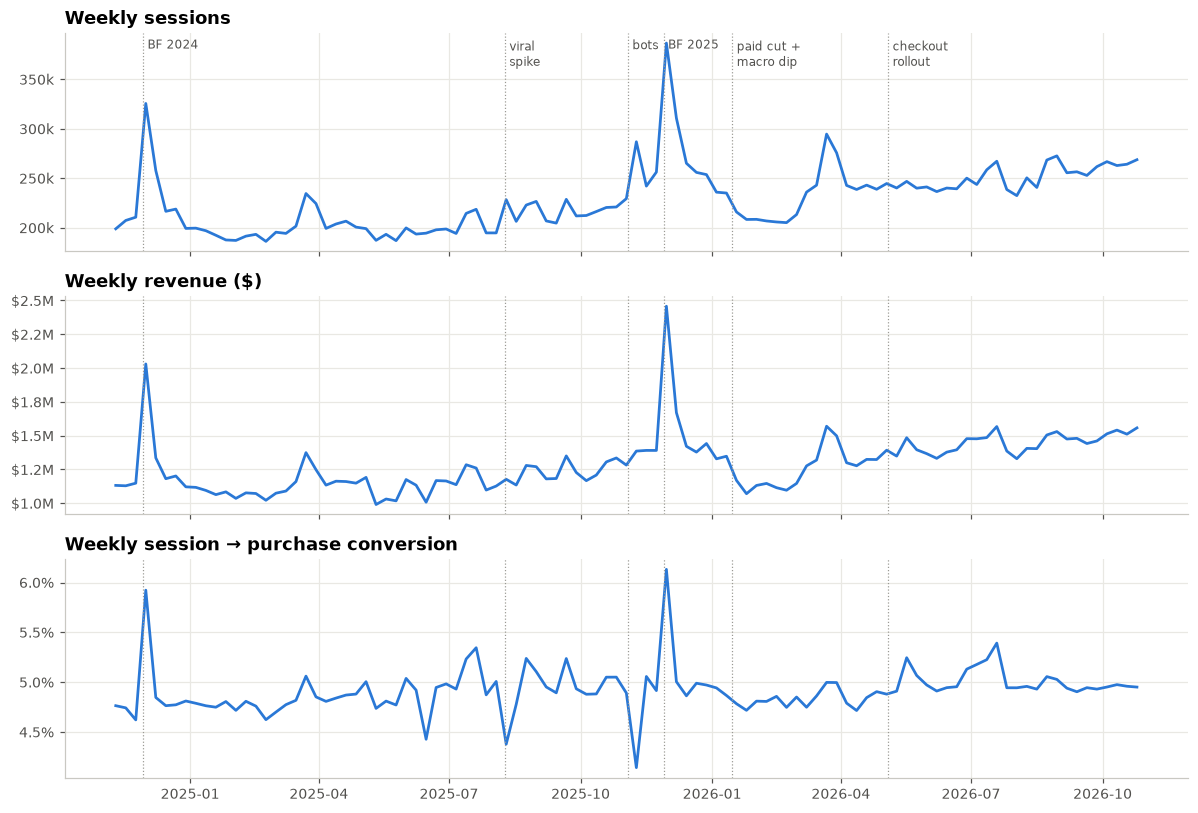

In [9]:
wk = daily.set_index("date").resample("W-SUN").agg({"sessions": "sum", "revenue": "sum", "purchased": "sum"}).iloc[1:-1]
wk["conversion"] = wk["purchased"] / wk["sessions"]
marks = [("2024-11-29", "BF 2024"), ("2025-08-09", "viral\nspike"), ("2025-11-03", "bots"), ("2025-11-28", "BF 2025"),
         ("2026-01-15", "paid cut +\nmacro dip"), ("2026-05-04", "checkout\nrollout")]
fig, axes = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True)
for ax, col, title, f in zip(axes, ["sessions", "revenue", "conversion"],
                             ["Weekly sessions", "Weekly revenue ($)", "Weekly session → purchase conversion"],
                             [lambda x, _: f"{x/1e3:.0f}k", lambda x, _: f"${x/1e6:.1f}M", lambda x, _: f"{x:.1%}"]):
    ax.plot(wk.index, wk[col], color=BLUE)
    ax.set_title(title); ax.yaxis.set_major_formatter(plt.FuncFormatter(f))
    for d_, lab in marks:
        ax.axvline(pd.Timestamp(d_), color=GREY, lw=0.8, ls=":")
for d_, lab in marks:
    axes[0].annotate(lab, (pd.Timestamp(d_), axes[0].get_ylim()[1]), xytext=(3, -4), textcoords="offset points",
                     va="top", fontsize=8, color=INK2)
save(fig, "01_weekly_trends")

### 4.1 Regression decomposition
For each daily series we fit `y = trend + weekday + annual seasonality + event dummies`, with
Newey–West (HAC, 7 lags) standard errors because daily residuals are autocorrelated. The response is
`log(sessions)`, `log(revenue)` and `logit(conversion)`, so coefficients read as relative changes.
P-values are adjusted for the number of terms tested (Benjamini–Hochberg).

In [10]:
def design():
    X = pd.DataFrame(index=np.arange(D))
    t = np.arange(D) / 365.25
    X["trend"] = t
    for k in range(1, 7):
        X[f"dow{k}"] = (DAYS.dayofweek == k).astype(float)
    for k in (1, 2, 3):
        X[f"sin{k}"] = np.sin(2 * np.pi * k * DAYS.dayofyear / 365.25)
        X[f"cos{k}"] = np.cos(2 * np.pi * k * DAYS.dayofyear / 365.25)
    for _, p in PR.iterrows():
        X[f"promo:{p.promo_id} {p['name']}"] = window(p.start_date, p.end_date).astype(float)
    bf_pre, bf_post = np.zeros(D), np.zeros(D)
    for _, p in PR[PR["type"].eq("sitewide % off")].iterrows():
        a, b = day_index(p.start_date), day_index(p.end_date)
        bf_pre[max(a - 7, 0):a] = 1; bf_post[b + 1:b + 8] = 1
    X["window:7 days before Black Friday"] = bf_pre
    X["window:7 days after Black Friday"] = bf_post
    for _, e in EV.iterrows():
        if e.type in ("experiment", "seasonality") or e.event_id in ("E02", "E05", "E13"):
            continue                      # experiments are balanced; loyalty / pet / defect are gradual or SKU-level;
                                          # category seasons do not move store totals (the harmonics carry total seasonality)
        X[f"event:{e.event_id} {e['name']}"] = window(e.start_date, e.end_date).astype(float)
    return sm.add_constant(X)

X = design()
y = {"sessions": np.log(daily["sessions"].values), "revenue": np.log(daily["revenue"].values),
     "conversion": np.log(daily["conversion"].values / (1 - daily["conversion"].values)),
     "aov": np.log(daily["aov"].values)}
rows = []
fits = {}
for name, yy in y.items():
    m = sm.OLS(yy, X).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
    m0 = sm.OLS(yy, X).fit()
    fits[name] = m
    # a dummy covering only a few days fits those days exactly, which makes robust SEs far too small;
    # take the larger of the HAC and the classical standard error (conservative)
    se = np.maximum(m.bse, m0.bse)
    for term in X.columns:
        if ":" in term or term == "trend":
            b = m.params[term]
            rows.append(dict(metric=name, term=term, days=int(X[term].sum()) if ":" in term else D,
                             effect=np.exp(b) - 1, lo=np.exp(b - 1.96 * se[term]) - 1, hi=np.exp(b + 1.96 * se[term]) - 1,
                             p=2 * stats.norm.sf(abs(b / se[term]))))
    print(f"{name:11s} R² = {m.rsquared:.3f}   residual sd = {np.sqrt(m.scale):.3f}   Durbin–Watson = {sm.stats.durbin_watson(m.resid):.2f}")
eff = pd.DataFrame(rows)
eff["p_adj"] = bh(eff["p"])
eff["sig"] = eff["p_adj"].map(stars)
eff.to_csv(OUT / "event_effects_regression.csv", index=False)

tab = eff.pivot(index="term", columns="metric", values="effect")[["sessions", "conversion", "aov", "revenue"]]
sig = eff.pivot(index="term", columns="metric", values="sig")[["sessions", "conversion", "aov", "revenue"]]
show = tab.map(lambda v: f"{v:+.1%}") + " " + sig
order = [c for c in X.columns if c in show.index]
print("\nEstimated effect of each factor (relative change vs. the modelled baseline; trend = per year)")
print("significance after Benjamini–Hochberg adjustment:  *** p<.001  ** p<.01  * p<.05  ns = not significant")
pd.set_option("display.width", 200, "display.max_colwidth", 60)
display(show.loc[order])

sessions    R² = 0.927   residual sd = 0.045   Durbin–Watson = 1.82
revenue     R² = 0.902   residual sd = 0.059   Durbin–Watson = 1.92
conversion  R² = 0.846   residual sd = 0.028   Durbin–Watson = 1.90
aov         R² = 0.362   residual sd = 0.037   Durbin–Watson = 1.89

Estimated effect of each factor (relative change vs. the modelled baseline; trend = per year)
significance after Benjamini–Hochberg adjustment:  *** p<.001  ** p<.01  * p<.05  ns = not significant


metric,sessions,conversion,aov,revenue
term,,,,
trend,+17.7% ***,+4.0% ***,-1.0% ns,+21.1% ***
promo:P01 Black Friday / Cyber Week 2024,+121.7% ***,+45.4% ***,-12.7% ***,+175.3% ***
promo:P02 Spring Sale 2025,+28.3% ***,+8.0% ***,-3.6% *,+33.1% ***
promo:P03 Summer Clearance 2025,+13.9% ***,+8.6% ***,-7.1% ***,+14.6% ***
promo:P04 Back to School 2025,+11.4% ***,+5.3% ***,-6.8% ***,+9.0% ***
promo:P05 LOYAL20 Member Flash Sale,+14.5% ***,+11.2% ***,-5.0% *,+20.1% ***
promo:P06 Free Shipping Weekend (Oct 2025),+3.7% ns,+8.0% ***,+5.0% *,+17.1% ***
promo:P07 Black Friday / Cyber Week 2025,+120.9% ***,+44.9% ***,-10.7% ***,+179.3% ***
promo:P08 Beauty BOGO Week,+0.4% ns,+1.7% ns,-0.8% ns,+1.2% ns


**Reading the table**

* **Trend**: sessions grow ~18% a year and revenue ~21%; growth is mostly traffic-led.
* **Black Friday / Cyber Week** more than doubles sessions, lifts conversion and — despite the 25% discount — nearly
  triples revenue. The 7 days **before and after** show depressed conversion and revenue: part of the lift is pulled
  forward from neighbouring weeks (quantified in notebook 03).
* **Traffic-only shocks** (viral mention, bot wave) raise sessions and *lower* the conversion rate while revenue barely moves:
  the extra visitors do not buy. Conversion rate alone would read these as bad days; orders say otherwise.
* **Incidents**: the site outage costs ~30% of a day's sessions; the mobile checkout bug and the card-payment outage hit
  conversion, not traffic.
* **Paid search budget cut** lowers sessions; its conversion coefficient is confounded with the macro slowdown that
  overlaps it — separated below.
* **Not significant** rows (e.g. Beauty BOGO on revenue) are as informative as the starred ones: no measurable sitewide effect.
* **Caveat on permanent changes**: dummies that stay on until the end of the data (price increase, checkout rollout) are
  poorly identified in a two-year regression — they are nearly collinear with the trend and seasonal terms, so their
  coefficients here should not be read as effects. Those changes are measured properly with a control group
  (difference-in-differences in notebook 02, the experiment in notebook 03).

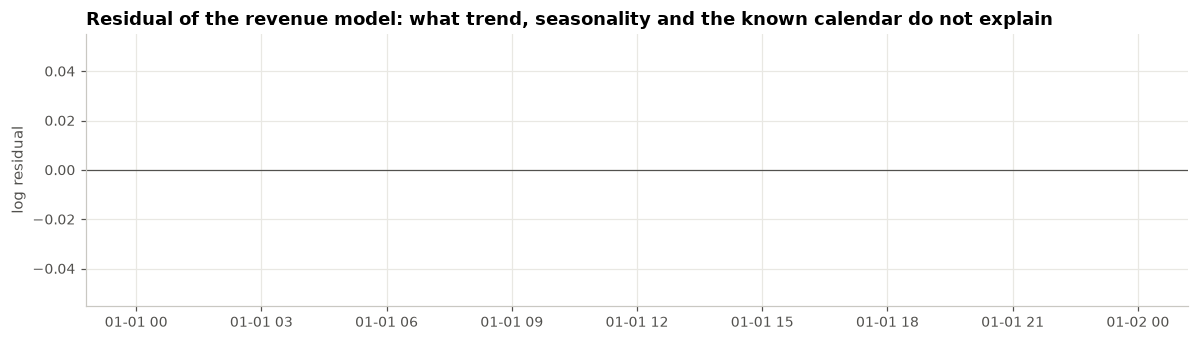

days beyond ±3 sd: 0 of 730 (expected by chance under normality: 2.0); residual sd = nan% of daily revenue
Once the calendar is in the model nothing unexplained is left. Notebook 04 does the reverse: it detects anomalies WITHOUT the calendar and then checks them against it.


In [11]:
fig, ax = plt.subplots(figsize=(11, 3.2))
res = pd.Series(fits["revenue"].resid, index=DAYS)
ax.plot(res.index, res, color=GREY, lw=0.9)
sd = res.std()
ax.axhline(0, color=INK2, lw=0.8)
for k in (-3, 3):
    ax.axhline(k * sd, color=BAD, lw=0.8, ls="--")
ax.set_title("Residual of the revenue model: what trend, seasonality and the known calendar do not explain")
ax.set_ylabel("log residual")
ax.annotate("±3 sd", (res.index[5], 3 * sd), xytext=(0, 4), textcoords="offset points", color=BAD, fontsize=8)
save(fig, "01_revenue_residual")
print(f"days beyond ±3 sd: {(res.abs() > 3 * sd).sum()} of {D} (expected by chance under normality: {D * 0.0027:.1f}); "
      f"residual sd = {sd:.1%} of daily revenue")
print("Once the calendar is in the model nothing unexplained is left. Notebook 04 does the reverse: it detects "
      "anomalies WITHOUT the calendar and then checks them against it.")

### 4.2 Mix shift vs rate change: the paid search budget cut (Jan–Feb 2026)
Paid Search converts below average, so halving it *raises* the blended conversion rate even if no channel
converts better. At the same time the macro slowdown lowers every channel's rate. The Kitagawa
decomposition splits the change in blended conversion into a **mix** component and a **rate** component.

In [12]:
def period(a, b):
    m = cube[cube["day"].between(day_index(a), day_index(b))]
    g = m.groupby("channel", observed=True)[["sessions", "purchased"]].sum()
    g["share"] = g["sessions"] / g["sessions"].sum()
    g["conv"] = g["purchased"] / g["sessions"]
    return g

pre, post = period("2025-10-06", "2025-11-02"), period("2026-01-26", "2026-02-22")   # 4 clean weeks each
blend_pre, blend_post = (pre["share"] * pre["conv"]).sum(), (post["share"] * post["conv"]).sum()
mix = ((post["share"] - pre["share"]) * (post["conv"] + pre["conv"]) / 2).sum()
rate = ((post["conv"] - pre["conv"]) * (post["share"] + pre["share"]) / 2).sum()
t = pd.DataFrame({"share before": pre["share"], "share during": post["share"], "conv before": pre["conv"], "conv during": post["conv"]})
t["conv change"] = t["conv during"] / t["conv before"] - 1
t["p (two-prop z)"] = [two_prop(pre.loc[c, "purchased"], pre.loc[c, "sessions"], post.loc[c, "purchased"], post.loc[c, "sessions"])["p"] for c in t.index]
display(t)
print(f"blended conversion: {blend_pre:.3%} → {blend_post:.3%}  (change {blend_post - blend_pre:+.3%} pts)")
print(f"   mix effect  (less Paid Search):        {mix:+.3%} pts")
print(f"   rate effect (within-channel change):   {rate:+.3%} pts")
pd.DataFrame({"component": ["blended before", "mix effect", "rate effect", "blended during"],
              "value": [blend_pre, mix, rate, blend_post]}).to_csv(OUT / "mix_shift_paid_cut.csv", index=False)

,share before,share during,conv before,conv during,conv change,p (two-prop z)
channel,,,,,,
Organic Search,0.2859,0.3206,0.0470,0.0449,-0.0458,0.0002
Paid Search,0.2209,0.1223,0.0455,0.0432,-0.0499,0.0046
Direct,0.1753,0.1945,0.0604,0.0573,-0.0501,0.0003
Social,0.1362,0.1591,0.0294,0.0281,-0.0445,0.0494
Email,0.1147,0.1306,0.0719,0.0708,-0.0148,0.3430
Affiliate,0.0669,0.0728,0.0502,0.0483,-0.0392,0.1156


blended conversion: 4.969% → 4.807%  (change -0.163% pts)
   mix effect  (less Paid Search):        +0.044% pts
   rate effect (within-channel change):   -0.206% pts


Every channel converts **worse** during the window (the macro slowdown: all six within-channel changes are negative,
four of them significant on their own), yet the blended rate falls by less than the within-channel rates because the
low-converting Paid Search share was cut almost in half. Reporting only the blended rate would hide a real, broad decline in purchase intent behind a
favourable mix change. This is the practical form of Simpson's paradox; segment-level rates should be the default view.